# L2B time series: Lac de Sainte-Croix

The Lac de Sainte-Croix (Alpes-de-Haute-Provence and Var, France) is a 22 km² reservoir of the Verdon
river, at the outlet of the Gorges du Verdon, known for its turquoise waters. This notebook explores
16 months of GRS **L2B** products (water-quality parameters computed from the L2A remote-sensing
reflectance) of the Sentinel-2 tile 31TGJ, in the middle of which the lake lies:

1. list the products of the tile and keep only those that see the lake: the tile is covered by three
   relative orbits, and two of them have no data over the lake;
2. build the multi-temporal L2B datacube of the lake with {meth}`grstbx.L2grs.get_l2b_datacube`,
   reading only the box around the lake and the variables needed;
3. select the images with enough valid water pixels;
4. describe the optical water types (OWT, Spyrakos et al., 2018) found in the lake;
5. map and follow the chlorophyll-a concentration (NASA OC2), the turbidity (Dogliotti et al., 2015) and
   the Secchi disk depth (Lee et al., 2015), and their seasonal cycle;
6. explore the parameters interactively with {class}`~grstbx.visual.ViewParam`.

```{note}
The L2B products are not distributed with grstbx: the notebook is rendered with the outputs of its
last run. Set the paths of the configuration cell to run it on your own data.
```

## Setup

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
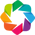

grstbx: 2.4.0


In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # noqa: F401, activates the .rio accessor
import matplotlib as mpl
import matplotlib.pyplot as plt
import panel as pn

import grstbx
from grstbx import visual
from grstbx.app import find_products, select_products

pn.extension()
warnings.filterwarnings('ignore', category=FutureWarning)   # xarray future defaults
warnings.filterwarnings('ignore', category=RuntimeWarning)  # statistics of all-NaN images
print(f'grstbx: {grstbx.__version__}')

Configuration: folder of the L2B products of the tile (tree `<tile>/YYYY/MM/DD/<product>`, full
tiles), centre and size of the box around the lake, period, minimum proportion of the lake that must
be valid to keep an image, and the parameters studied with their colour range.

In [2]:
L2B_DIR = '/data/satellite/Sentinel-2/L2B_zarr'
TILE = '31TGJ'
LAKE = 'Lac de Sainte-Croix'
LON, LAT = 6.180, 43.754              # centre of the lake
WIDTH, HEIGHT = 13000, 14000          # box around the lake (m)
START_DATE, END_DATE = '2025-01-01', '2026-12-31'
MIN_LAKE_FRACTION = 0.5               # minimum proportion of valid lake pixels
OWT = 'owt_index_Spyrakos2018'
PARAMS = {'Chla_OC2nasa': (r'$Chl\text{-}a\ (mg\ m^{-3})$', (0.5, 3)),
          'TURB_dogliotti': (r'$Turbidity\ (FNU)$', (0, 5)),
          'Zsd_Lee15': (r'$Secchi\ depth\ (m)$', (0, 8))}

## 1. Products over the lake

{func}`~grstbx.app.find_products` lists the products of the tile from their names, without opening
them, and {func}`~grstbx.app.select_products` keeps the last processing of each acquisition over the
period. The relative orbit (`R008`, `R065`, `R108`) is read from the names too.

In [3]:
products = select_products(find_products(os.path.join(L2B_DIR, TILE)), tile=TILE,
                           start=START_DATE, end=END_DATE)
products['orbit'] = products.name.str.extract(r'_(R\d{3})_', expand=False)
print(f'{len(products)} L2B products from {products.time.min():%Y-%m-%d} to {products.time.max():%Y-%m-%d}')
products.groupby('orbit').time.agg(['count', 'min', 'max'])

240 L2B products from 2025-01-01 to 2026-04-30


,count,min,max
orbit,,,
R008,78,2025-01-01 10:44:41,2026-04-21 10:36:19
R065,79,2025-01-10 10:23:19,2026-04-30 10:20:21
R108,83,2025-01-03 10:33:39,2026-04-28 10:30:19


Tile 31TGJ is covered by the swaths of three relative orbits, but the lake is seen by only one of them:
the products of the other orbits have no data over the lake (or only over a strip at the edge of the
tile) and should not be opened. The coverage of each orbit is checked on the `mask` of the box around
the lake, for four products per orbit only (a few seconds), and the products of the orbits without any
valid pixel are discarded:

In [4]:
aoi = grstbx.aoi_from_box(LON, LAT, width=WIDTH, height=HEIGHT)
reader = grstbx.L2grs([])
coverage = {}
for orbit, group in products.groupby('orbit'):
    sample = group.path.iloc[np.linspace(0, len(group) - 1, 4).astype(int)]
    coverage[orbit] = [int((reader.subset_xy(reader.load_l2b_image(path)[['mask']], aoi).mask == 0).sum())
                       for path in sample]
coverage = pd.DataFrame(coverage, index=[f'product {i + 1}' for i in range(4)])
print('valid pixels in the box around the lake:')
display(coverage)

orbits = coverage.columns[coverage.sum() > 0]
files = products[products.orbit.isin(orbits)].path.values
print(f'orbit(s) kept: {", ".join(orbits)}: {len(files)} products out of {len(products)}')

valid pixels in the box around the lake:


,R008,R065,R108
product 1,0,0,50591
product 2,0,0,53064
product 3,0,0,42769
product 4,0,0,52962


orbit(s) kept: R108: 83 products out of 240


## 2. L2B datacube

The products are full tiles (5490 x 5490 pixels at 20 m, about 25 variables): the datacube is built
from the box around the lake only, and from the variables studied (`variables=`), so that only a few
MB are read from each file. {meth}`~grstbx.driver.L2grs.get_l2b_datacube` skips the images without
any valid Chl-a pixel (e.g. fully cloudy over the lake) and adds the proportion of valid pixels
(`valid_pix_prop`).

In [5]:
t0 = time.time()
dc = grstbx.L2grs(files)
dc.get_l2b_datacube(subset=aoi, var='Chla_OC2nasa', variables=[OWT, *PARAMS, 'mask'])
# scalar coordinates of the ancillary data are not needed; float32 halves the memory
datacube = dc.datacube.drop_vars(['band', 'wl', 'forecast_period', 'forecast_reference_time'],
                                 errors='ignore')
datacube = datacube.map(lambda v: v.astype('float32') if v.dtype == 'float64' else v)
datacube[OWT] = datacube[OWT].isel(Nclasses=0)     # closest optical water type
print(f"{datacube.sizes['time']} images out of {len(files)}, {datacube.sizes['y']} x {datacube.sizes['x']} "
      f'pixels, {datacube.rio.crs}, read in {time.time() - t0:.0f} s')
datacube

79 images out of 83, 725 x 677 pixels, EPSG:32631, read in 22 s


<xarray.Dataset> Size: 659MB
Dimensions:                 (x: 677, y: 725, time: 79, Nclasses: 3)
Coordinates:
  * x                       (x) float64 5kB 7.492e+05 7.493e+05 ... 7.628e+05
  * y                       (y) float64 6kB 4.857e+06 4.857e+06 ... 4.842e+06
  * time                    (time) datetime64[ns] 632B 2025-01-03T10:33:39 .....
  * Nclasses                (Nclasses) int64 24B 0 1 2
    spatial_ref             int32 4B ...
Data variables:
    Chla_OC2nasa            (time, y, x) float32 155MB nan nan nan ... nan nan
    owt_index_Spyrakos2018  (time, y, x) float32 155MB nan nan nan ... nan nan
    TURB_dogliotti          (time, y, x) float32 155MB nan nan nan ... nan nan
    Zsd_Lee15               (time, y, x) float32 155MB nan nan nan ... nan nan
    mask                    (time, y, x) uint8 39MB 1 1 1 1 1 1 ... 1 1 1 1 1 1
    valid_pix_prop          (time) float32 316B 0.1022 0.102 ... 0.1075 0.1077
Attributes: (12/79)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /work/datalake/watcal/L1C/31TGJ/2025...
    product_name:                        S2B_MSIL1C_20250103T103339_N0511_R10...
    instrument:                          MSI
    ...                                  ...
    abs_gas_file:                        /work/scratch/data/harmelt/git/GRSpr...
    water_vapor_transmittance_file:      /work/scratch/data/harmelt/git/GRSpr...
    GRSdriver_version:                   2.0.1
    metadata_profile:                    datacube
    start_date:                          2025-01-03T10:33:39.000000000
    stop_date:                           2026-04-28T10:30:19.000000000

## 3. Image selection

The lake is defined as the pixels valid (`mask == 0`) in at least 30 % of the images: this removes the
land pixels occasionally classified as water, and the shores uncovered when the water level is low.
The analysis is restricted to the lake pixels, and an image is kept when more than
`MIN_LAKE_FRACTION` of the lake is valid (clouds, cloud shadows and haze are masked).

lake: 52794 pixels (21.1 km²); 67 images out of 79 kept


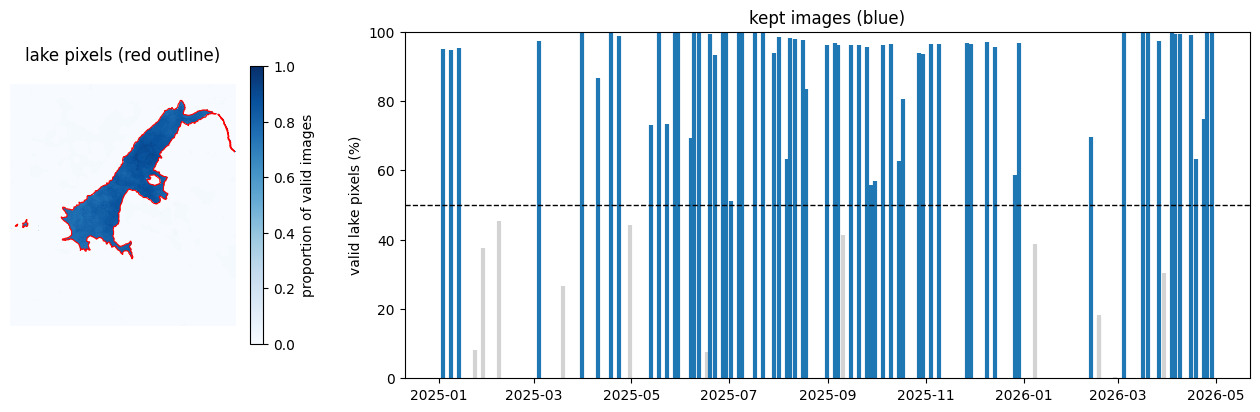

In [6]:
valid = (datacube.mask == 0) & datacube['Chla_OC2nasa'].notnull()
lake = valid.mean('time') >= 0.3
lake_fraction = valid.where(lake).sum(['x', 'y']) / lake.sum()
good = lake_fraction >= MIN_LAKE_FRACTION
cube = datacube.where(valid & lake).sel(time=good)
pixel_area = abs(np.prod(datacube.rio.resolution())) / 1e6
print(f'lake: {int(lake.sum())} pixels ({lake.sum().values * pixel_area:.1f} km²); '
      f'{int(good.sum())} images out of {datacube.sizes["time"]} kept')

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 3]})
valid.mean('time').plot.imshow(ax=axs[0], cmap='Blues', vmin=0, vmax=1, add_labels=False,
                               cbar_kwargs={'label': 'proportion of valid images', 'shrink': 0.8})
lake.plot.contour(ax=axs[0], levels=[0.5], colors='r', linewidths=0.8, add_labels=False)
axs[0].set_aspect('equal')
axs[0].set_axis_off()
axs[0].set_title('lake pixels (red outline)')
axs[1].vlines(lake_fraction.time.values, 0, lake_fraction * 100, lw=3,
              colors=np.where(good, 'tab:blue', 'lightgrey'))
axs[1].axhline(MIN_LAKE_FRACTION * 100, c='k', ls='--', lw=1)
axs[1].set_ylabel('valid lake pixels (%)')
axs[1].set_ylim(0, 100)
axs[1].set_title('kept images (blue)');

## 4. Optical water types

Each pixel is assigned the closest of the 13 optical water types of Spyrakos et al. (2018), defined
in the `definition` attribute of the variable. Distribution of the types over all the kept images,
and dominant type of the lake for each image:

OWT 3: 95.6 %, OWT 9: 1.5 %, OWT 13: 1.1 %


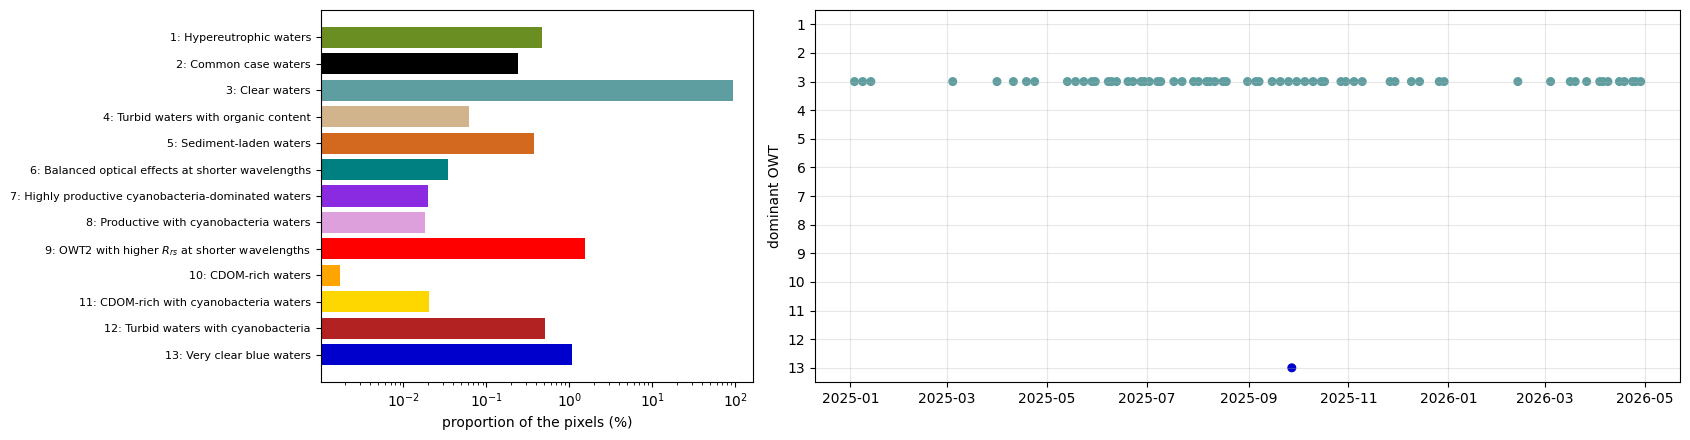

In [7]:
definition = datacube[OWT].attrs['definition'].strip().splitlines()
owt_labels = {int(line.split(':')[0]): line.split(':', 2)[2].strip() for line in definition}
owt_colors = ['olivedrab', 'black', 'cadetblue', 'tan', 'chocolate', 'teal', 'blueviolet', 'plum', 'red',
              'orange', 'gold', 'firebrick', 'mediumblue']
cmap_owt = mpl.colors.ListedColormap(owt_colors)

owt = cube[OWT].values.ravel()
owt = owt[np.isfinite(owt)].astype(int)
classes = np.arange(1, 14)
freq = np.array([(owt == c).mean() for c in classes])
dominant = cube[OWT].to_dataframe()[OWT].dropna().groupby(level='time').agg(lambda s: s.mode().iloc[0])

fig, axs = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1, 2]})
axs[0].barh(classes, freq * 100, color=owt_colors)
axs[0].set_yticks(classes, [f'{c}: {owt_labels[c]}' for c in classes], fontsize=8)
axs[0].invert_yaxis()
axs[0].set_xscale('log')
axs[0].set_xlabel('proportion of the pixels (%)')
axs[1].scatter(dominant.index, dominant.values, c=dominant.values, cmap=cmap_owt, vmin=0.5, vmax=13.5, s=30)
axs[1].set_yticks(classes)
axs[1].set_ylim(13.5, 0.5)
axs[1].set_ylabel('dominant OWT')
axs[1].grid(alpha=0.3)
fig.tight_layout()
print(', '.join(f'OWT {c}: {f * 100:.1f} %' for c, f in zip(classes, freq) if f >= 0.01))

The lake is dominated by the clear waters of OWT 3 (more than 95 % of the pixels, and dominant type of
almost every image), as expected for this oligotrophic reservoir; each of the other types covers less
than 2 % of the pixels.

## 5. Chlorophyll-a, turbidity and transparency

Maps of one image every two months (first kept image of the month), one row per parameter:

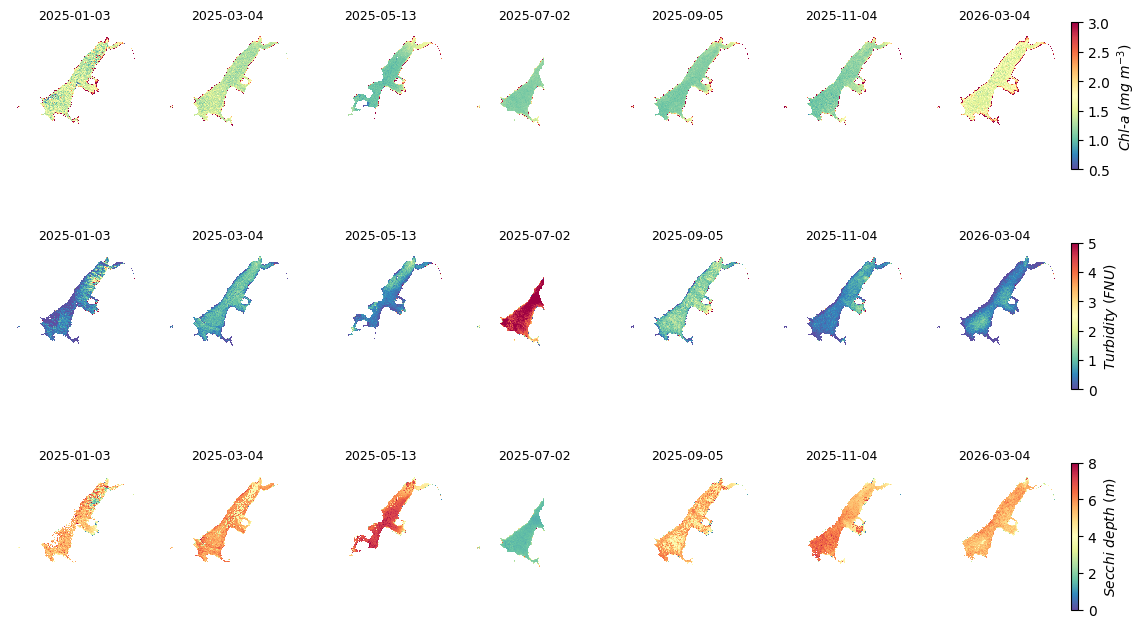

In [8]:
times = cube.time.to_series()
monthly = times.groupby(times.dt.to_period('M')).first()
monthly = monthly[monthly.index.month % 2 == 1].values[:8]
fig, axs = plt.subplots(len(PARAMS), len(monthly), figsize=(len(monthly) * 2.3, len(PARAMS) * 2.7),
                        squeeze=False)
for row, (param, (label, (vmin, vmax))) in zip(axs, PARAMS.items()):
    for ax, date in zip(row, monthly):
        im = cube[param].sel(time=date).plot.imshow(ax=ax, cmap='Spectral_r', vmin=vmin, vmax=vmax,
                                                    add_colorbar=False, add_labels=False)
        ax.set_title(f'{pd.Timestamp(date):%Y-%m-%d}', fontsize=9)
        ax.set_axis_off()
        ax.set_aspect('equal')
    fig.colorbar(im, ax=row, shrink=0.8, pad=0.01, label=label)

Median and variability (inter-quartile range) of each pixel over all the kept images: the turbidity is
higher and the water slightly less transparent in the arm of the Verdon inflow (north-east) than in the
main basin, where the transparency varies the most over time. The higher Chl-a values along the shores
come from mixed land-water pixels and from the adjacency effect of the bright surroundings, not from
the water.

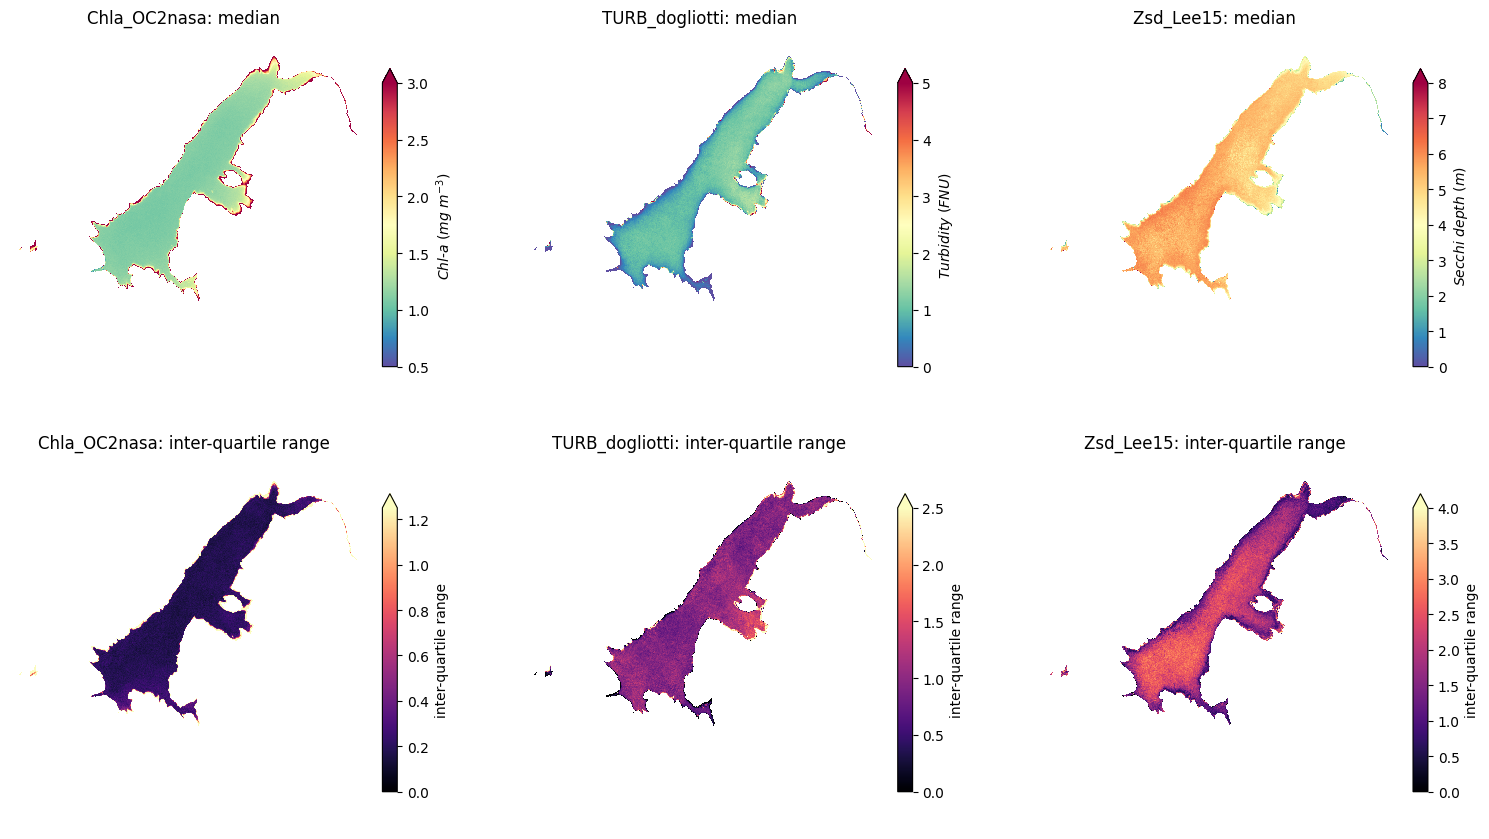

In [9]:
fig, axs = plt.subplots(2, len(PARAMS), figsize=(5.2 * len(PARAMS), 8.5), squeeze=False)
for col, (param, (label, (vmin, vmax))) in enumerate(PARAMS.items()):
    quartiles = cube[param].quantile([0.25, 0.5, 0.75], 'time')
    quartiles.sel(quantile=0.5).plot.imshow(ax=axs[0, col], cmap='Spectral_r', vmin=vmin, vmax=vmax,
                                            add_labels=False, cbar_kwargs={'label': label, 'shrink': 0.8})
    (quartiles.sel(quantile=0.75) - quartiles.sel(quantile=0.25)).plot.imshow(
        ax=axs[1, col], cmap='magma', vmin=0, vmax=(vmax - vmin) / 2, add_labels=False,
        cbar_kwargs={'label': 'inter-quartile range', 'shrink': 0.8})
    axs[0, col].set_title(f'{param}: median')
    axs[1, col].set_title(f'{param}: inter-quartile range')
for ax in axs.ravel():
    ax.set_axis_off()
    ax.set_aspect('equal')
fig.tight_layout()

Time series of the lake median (dots) and inter-quartile range (bars):

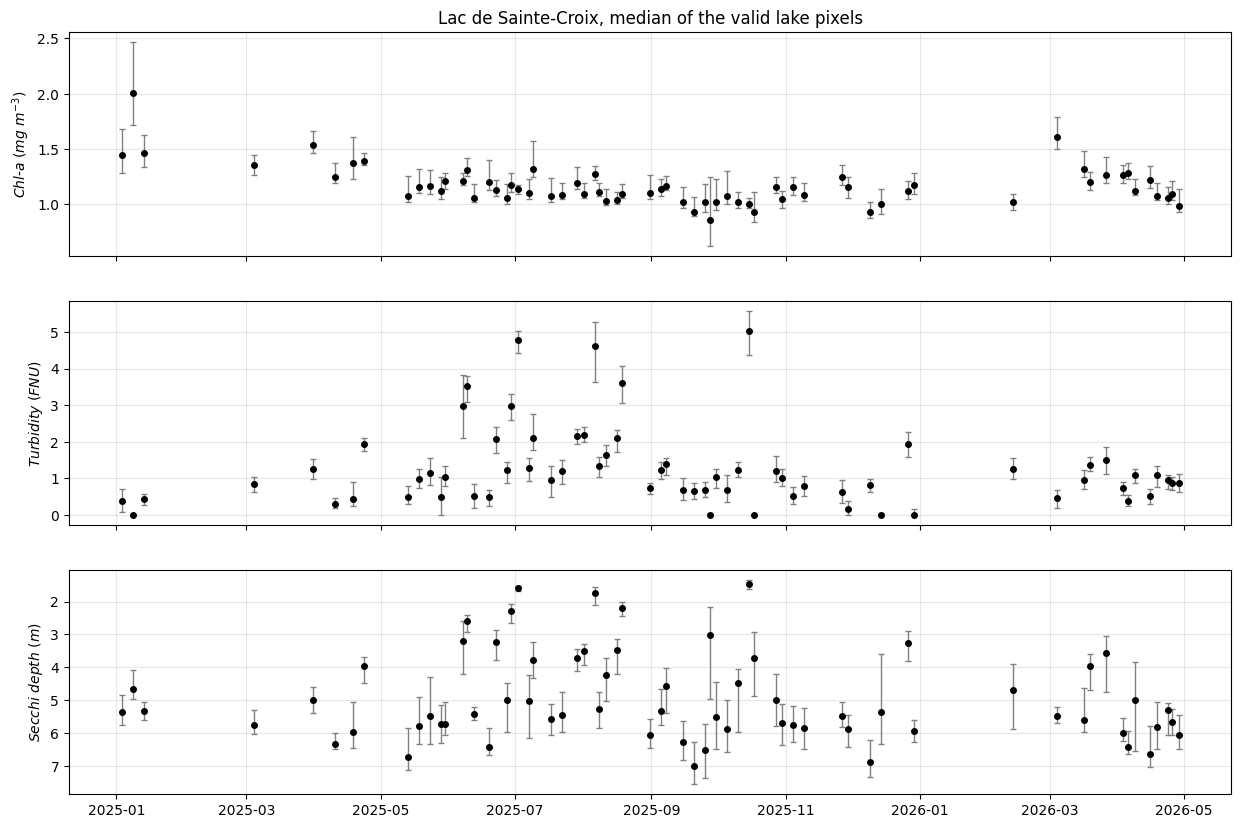

In [10]:
stats = {param: cube[param].quantile([0.25, 0.5, 0.75], ['x', 'y']).to_pandas().T for param in PARAMS}
fig, axs = plt.subplots(len(PARAMS), 1, figsize=(15, 3.3 * len(PARAMS)), sharex=True)
for ax, (param, (label, _)) in zip(axs, PARAMS.items()):
    q = stats[param]
    ax.errorbar(q.index, q[0.5], yerr=[q[0.5] - q[0.25], q[0.75] - q[0.5]], fmt='o', c='k', ms=4,
                ecolor='grey', capsize=2, lw=1)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3, which='both')
axs[2].invert_yaxis()   # Secchi depth: deeper downwards
axs[0].set_title(f'{LAKE}, median of the valid lake pixels');

The chlorophyll-a stays low all year round (about 1 mg m⁻³, oligotrophic waters), while the turbidity
rises and the Secchi depth drops from 5-7 m to 1.5-3 m on several dates from June to October. Seasonal
cycle of the lake median per month (all years):

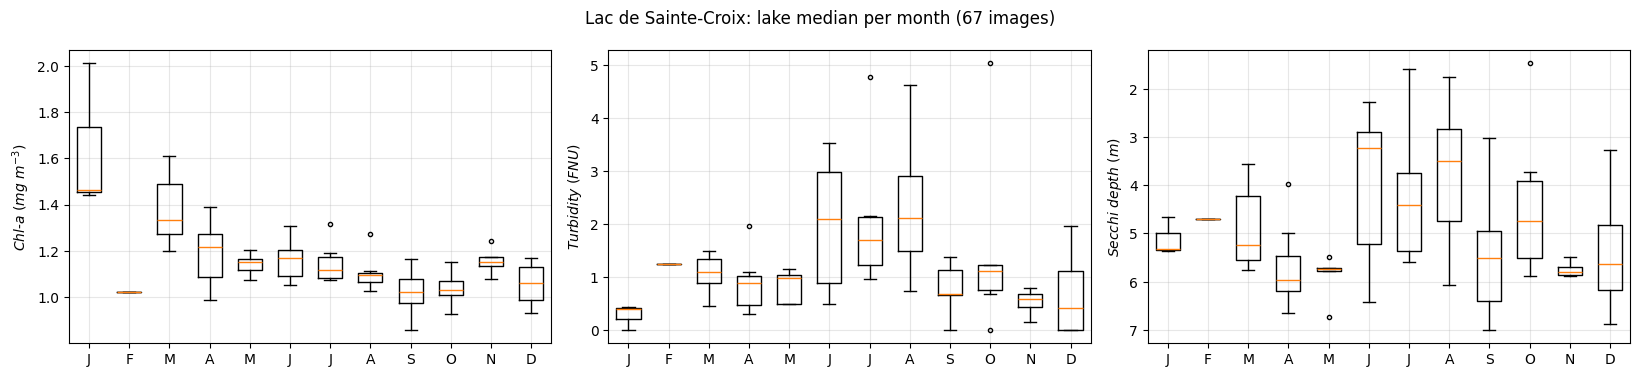

In [11]:
medians = pd.DataFrame({param: q[0.5] for param, q in stats.items()})
fig, axs = plt.subplots(1, len(PARAMS), figsize=(5.5 * len(PARAMS), 3.8))
for ax, (param, (label, _)) in zip(axs, PARAMS.items()):
    monthly_values = [medians[param][medians.index.month == m].dropna() for m in range(1, 13)]
    ax.boxplot(monthly_values, positions=range(1, 13), widths=0.6, showfliers=True,
               flierprops={'markersize': 3})
    ax.set_xticks(range(1, 13), ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axs[2].invert_yaxis()
fig.suptitle(f'{LAKE}: lake median per month ({cube.sizes["time"]} images)')
fig.tight_layout()

The Secchi depth of Lee et al. (2015) is computed from the diffuse attenuation, itself driven by the
particles in this clear lake: the two parameters, retrieved by independent algorithms, are consistent
(lake medians of each image, coloured by month). The few images with a turbidity of zero and a
Secchi depth of 3-5 m (autumn and winter) depart from the relationship: they are probably affected by
residual haze or by an imperfect atmospheric correction, and should be checked before any trend
analysis.

Spearman correlation: -0.69


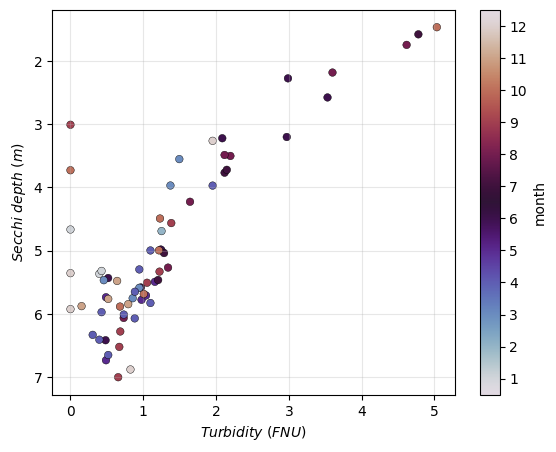

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(medians['TURB_dogliotti'], medians['Zsd_Lee15'], c=medians.index.month, cmap='twilight',
                vmin=0.5, vmax=12.5, s=30, edgecolor='k', lw=0.3)
ax.set(xlabel=PARAMS['TURB_dogliotti'][0], ylabel=PARAMS['Zsd_Lee15'][0])
ax.invert_yaxis()
ax.grid(alpha=0.3)
fig.colorbar(sc, ax=ax, ticks=range(1, 13), label='month')
print(f"Spearman correlation: {medians['TURB_dogliotti'].corr(medians['Zsd_Lee15'], method='spearman'):.2f}")

## 6. Interactive exploration

{class}`~grstbx.visual.ViewParam` displays all the parameters of the datacube over a basemap, with
date, parameter, colormap and colour range selectors; hover the map with *Live* checked to plot the
time series under the mouse. The interactive widgets are not functional in the rendered
documentation. The same products can be explored without notebook in the web dashboard
(see {doc}`../dashboard`):

```
grstbx-viewer /data/satellite/Sentinel-2/L2B_zarr/31TGJ --tile 31TGJ
```

In [13]:
viewer = visual.ViewParam(cube[list(PARAMS)], reproject=True, minmaxvalues=(0, 5), minmax=(0, 10),
                          basemap='CARTO Positron')
viewer.visu()

Column
    [0] WidgetBox(stylesheets=[':host { overflow: v...])
        [0] Markdown(str)
        [1] Column(stylesheets=[':host { overflow: v...])
            [0] Row(stylesheets=[':host { overflow: v...])
                [0] Markdown(str)
                [1] Select(options=['Chla_OC2nasa', ...], value='Chla_OC2nasa')
                [2] Checkbox(name='Live time series', value=True)
            [1] Row(stylesheets=[':host { overflow: v...])
                [0] Row(stylesheets=[':host { overflow: v...])
                    [0] Markdown(str)
                    [1] Select(options={'2025-01-03 10:33:39': 0,...}, value=0)
                [1] Row(stylesheets=[':host { overflow: v...])
                    [0] Markdown(str)
                    [1] Select(options=['CARTO Positron', ...], value='CARTO Positron')
            [2] Row(stylesheets=[':host { overflow: v...])
                [0] EditableRangeSlider(end=10, name='Range Slider', step=0.0001, value=(0, 5), width=300)
                [1] Row(stylesheets=[':host { overflow: v...])
                    [0] Markdown(str)
                    [1] FloatSlider(name='Opacity', step=0.05, value=0.95)
            [3] Row(stylesheets=[':host { overflow: v...])
                [0] Markdown(str)
                [1] ColorMap(options={'Rainbow (CET_R1)': ['#00...}, swatch_width=120, value=['#0030f5', '#0034f2', ...], value_name='Rainbow (CET_R1)', width=260)
                [2] Column(stylesheets=[':host { overflow: v...])
                    [0] Checkbox(name='Reverse')
                    [1] Checkbox(name='Log scale')
            [4] Row(stylesheets=[':host { overflow: v...])
                [0] Markdown(str)
                [1] FloatSlider(end=4.0, name='Contrast', start=0.2, step=0.05, value=1.0)
                [2] FloatSlider(end=0.5, name='Brightness', start=-0.5, step=0.01)
    [1] HoloViews(DynamicMap, height=700, sizing_mode='fixed', width=1000)
    [2] HoloViews(DynamicMap, height=350, sizing_mode='fixed', width=1000)

**References**

- Dogliotti, A. I., et al. (2015). A single algorithm to retrieve turbidity from remotely-sensed data
  in all coastal and estuarine waters. *Remote Sensing of Environment*, 156, 157-168.
- Lee, Z., et al. (2015). Secchi disk depth: a new theory and mechanistic model for underwater
  visibility. *Remote Sensing of Environment*, 169, 139-149.
- O'Reilly, J. E., et al. (1998). Ocean color chlorophyll algorithms for SeaWiFS. *Journal of
  Geophysical Research*, 103(C11), 24937-24953.
- Spyrakos, E., et al. (2018). Optical types of inland and coastal waters. *Limnology and
  Oceanography*, 63(2), 846-870.